# Lab 1 — Phishing URL Detection with SVM and KNN

**Scenario:** You are a Security Operations Center (SOC) analyst. Your task is to assess whether a URL is **phishing** or **legitimate** using selected features that describe the URL's structure—without opening the URL itself. You will compare a transparent rule-based baseline with two supervised machine-learning classifiers: **Support Vector Machine (SVM)** with an RBF kernel and **K-Nearest Neighbors (KNN)**.

The goal is not simply to obtain the highest score. In a security workflow, you must also understand which errors each model makes, how configuration choices affect the results, and why a model prediction should be treated as one piece of evidence rather than as an automatic authorization to take action.

**Dataset:** This lab uses the **PhiUSIIL Phishing URL Dataset** from the UCI Machine Learning Repository. The dataset page reports 235,795 examples, 54 features, and two classes. It includes features derived from URLs and associated web pages. The original target labels are `1 = legitimate` and `0 = phishing`. In this notebook, the target is converted to `is_phishing`, where `1` means phishing and `0` means legitimate. Be careful to keep this convention in mind when interpreting metrics and confusion matrices.

Dataset page: https://archive.ics.uci.edu/dataset/967/phiusil-phishing-url-dataset

## Step 1 — Set up the environment

The notebook is designed to run in Google Colab. The next cell installs the small `ucimlrepo` package used to download the dataset from the UCI Machine Learning Repository. Running the installation requires an internet connection.

Run the cells in order, from top to bottom. If you restart the runtime, run the setup and data-loading cells again before continuing.


In [ ]:
%pip -q install ucimlrepo

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

RANDOM_STATE = 42
print("Environment ready.")

Environment ready.


## Step 2 — Download the UCI dataset

The following cell retrieves dataset ID `967` from the UCI Machine Learning Repository and separates the feature table from the original target labels. It also prints basic information so you can confirm that the dataset has loaded and inspect the target encoding before preprocessing it.

The first download may take a little time depending on your connection and the availability of the data source.


In [ ]:
# Dataset UCI ID 967: PhiUSIIL Phishing URL
phiusiil = fetch_ucirepo(id=967)
X_all = phiusiil.data.features.copy()
y_raw = pd.to_numeric(phiusiil.data.targets.iloc[:, 0], errors="coerce")

print("Feature matrix shape:", X_all.shape)
print("Target column:", phiusiil.data.targets.columns[0])
print("Observed target values:", sorted(y_raw.dropna().unique().tolist()))
print("First columns:", X_all.columns[:12].tolist())

Feature matrix shape: (235795, 54)
Target column: label
Observed target values: [0, 1]
First columns: ['URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain']


### Why not use every column?

The dataset includes textual and identifying fields such as `URL`, `Domain`, and `Title`, as well as features calculated from the associated web page. Those fields are not all suitable for the scenario in this exercise: a SOC filter may need to assess a URL **before visiting the destination page**, so page-derived information might not yet be available.

For this reason, the models use a selected set of numeric features that describe URL structure. The raw URL strings are not displayed. The `Domain` column is kept separately for the optional group-based evaluation later in the notebook; it is used to define which domains appear in training versus test data, not to make predictions.


## Step 3 — Select features and explore the data

This step selects the URL-structure features used by the models, converts them to numeric values, handles invalid or missing entries, and maps the original UCI labels to the lab's target convention:

- `0` = legitimate
- `1` = phishing

You will also inspect the class distribution and descriptive statistics. These checks are important: unexpected labels, missing columns, or unusual feature ranges can affect subsequent experiments. Review the output before moving on.


Usable rows after cleaning: 235795
Number of features used by the models: 19
Missing values in selected features: 0

Class distribution (1 = phishing):
is_phishing
Legitimate (0)    134850
Phishing (1)      100945
Name: count, dtype: int64


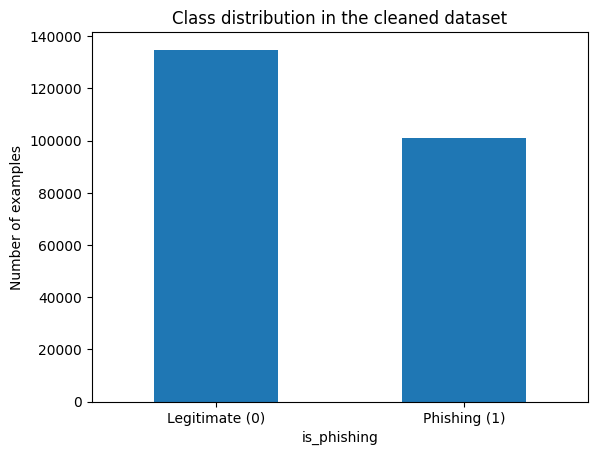

,count,mean,std,min,25%,50%,75%,max
URLLength,235795.0,34.57,41.31,13.0,23.00,27.00,34.00,6097.00
DomainLength,235795.0,21.47,9.15,4.0,16.00,20.00,24.00,110.00
IsDomainIP,235795.0,0.00,0.05,0.0,0.00,0.00,0.00,1.00
CharContinuationRate,235795.0,0.85,0.22,0.0,0.68,1.00,1.00,1.00
TLDLength,235795.0,2.76,0.60,2.0,2.00,3.00,3.00,13.00
NoOfSubDomain,235795.0,1.16,0.60,0.0,1.00,1.00,1.00,10.00
HasObfuscation,235795.0,0.00,0.05,0.0,0.00,0.00,0.00,1.00
NoOfObfuscatedChar,235795.0,0.02,1.88,0.0,0.00,0.00,0.00,447.00
ObfuscationRatio,235795.0,0.00,0.00,0.0,0.00,0.00,0.00,0.35
NoOfLettersInURL,235795.0,19.43,29.09,0.0,10.00,14.00,20.00,5191.00


In [ ]:
URL_FEATURES = [
    "URLLength", "DomainLength", "IsDomainIP", "CharContinuationRate",
    "TLDLength", "NoOfSubDomain", "HasObfuscation", "NoOfObfuscatedChar",
    "ObfuscationRatio", "NoOfLettersInURL", "LetterRatioInURL",
    "NoOfDegitsInURL", "DegitRatioInURL", "NoOfEqualsInURL",
    "NoOfQMarkInURL", "NoOfAmpersandInURL", "NoOfOtherSpecialCharsInURL",
    "SpacialCharRatioInURL", "IsHTTPS"
]

missing_columns = [c for c in URL_FEATURES if c not in X_all.columns]
if missing_columns:
    raise ValueError(f"Expected columns are missing from the dataset: {missing_columns}")

# Original UCI labels: 0 = phishing, 1 = legitimate. Map phishing to 1 for this lab.
data = X_all[URL_FEATURES].apply(pd.to_numeric, errors="coerce")
data["is_phishing"] = (y_raw == 0).astype(int)

# Keep Domain only for the unseen-domain evaluation extension; do not use it as a model feature.
if "Domain" in X_all.columns:
    data["domain_group"] = X_all["Domain"].fillna("unknown").astype(str).str.lower()
else:
    data["domain_group"] = X_all.index.astype(str)

data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=URL_FEATURES + ["is_phishing"]).copy()

print("Usable rows after cleaning:", len(data))
print("Number of features used by the models:", len(URL_FEATURES))
print("Missing values in selected features:", int(data[URL_FEATURES].isna().sum().sum()))
print("\nClass distribution (1 = phishing):")
print(data["is_phishing"].value_counts().sort_index().rename(index={0: "Legitimate (0)", 1: "Phishing (1)"}))

data["is_phishing"].value_counts().sort_index().plot(kind="bar")
plt.xticks([0, 1], ["Legitimate (0)", "Phishing (1)"], rotation=0)
plt.ylabel("Number of examples")
plt.title("Class distribution in the cleaned dataset")
plt.show()

display(data[URL_FEATURES].describe().T.round(2).head(12))

## Step 4 — Create a reproducible sample and split the data

Kernel-based SVM and KNN can be computationally expensive on a large dataset. The notebook therefore selects at most 6,000 rows with stratified sampling and a fixed random seed. This makes the experiment quicker and reproducible, while keeping the class proportions approximately consistent with the cleaned data.

The sampled data is divided into **75% training data** and **25% test data**, using stratification on the target. The models are fitted on the training portion and evaluated on the held-out test portion. Do not tune model settings on the test set as if it were validation data; for this short lab, the test metrics are intended for comparison and interpretation, and extensive hyperparameter optimization would ideally use a separate validation strategy.


In [ ]:
# RBF SVM and KNN can be computationally expensive on the full dataset.
# Use stratified sampling to preserve the class proportions.
MAX_ROWS = 6000
if len(data) > MAX_ROWS:
    sample_data, _ = train_test_split(
        data, train_size=MAX_ROWS, stratify=data["is_phishing"],
        random_state=RANDOM_STATE
    )
else:
    sample_data = data.copy()

sample_data = sample_data.reset_index(drop=True)
X = sample_data[URL_FEATURES].copy()
y = sample_data["is_phishing"].astype(int)
groups = sample_data["domain_group"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

print(f"Sample: {len(sample_data)} rows")
print(f"Training: {len(X_train)} | Test: {len(X_test)}")
print("Phishing proportion in training set:", round(y_train.mean(), 3))
print("Phishing proportion in test set:", round(y_test.mean(), 3))

Sample: 6000 rows
Training: 4500 | Test: 1500
Phishing proportion in training set: 0.428
Phishing proportion in test set: 0.428


## Step 5 — Establish a rule-based baseline

Before training machine-learning models, evaluate a simple rule. In a real SOC, a baseline helps answer a practical question: do more complex models improve on a transparent, easy-to-explain approach?

A baseline is not ground truth and should not be assumed to be either strong or weak in advance. Its value is that its decisions can be inspected and its thresholds can be changed directly.


The rule marks a URL as potentially suspicious if **at least one** of these conditions is met: the URL length is 75 or more characters, the domain is represented as an IP address, an obfuscation indicator is present, or the URL has at least three subdomains.

These thresholds are illustrative, not universal indicators of phishing. Legitimate URLs can be long or complex, while malicious URLs can be short and visually ordinary. After running the baseline, consider changing one threshold at a time and observe how the number and type of alerts change. Keep the same test set when comparing the rule with SVM and KNN.


In [ ]:
def rule_detector(frame):
    return (
        (frame["URLLength"] >= 75)
        | (frame["IsDomainIP"] == 1)
        | (frame["HasObfuscation"] == 1)
        | (frame["NoOfSubDomain"] >= 3)
    ).astype(int)

rule_pred = rule_detector(X_test)
print("Number of alerts generated by the rule:", int(rule_pred.sum()), "out of", len(rule_pred))

Number of alerts generated by the rule: 94 out of 1500


## Step 6 — Evaluate the baseline consistently

The helper function below calculates the same metrics for each method, allowing an apples-to-apples comparison on the same test examples.

The positive class is **phishing (`1`)**. Therefore:

- **Accuracy** is the proportion of all test examples classified correctly.
- **Phishing precision** is the proportion of URLs predicted as phishing that are actually labelled phishing.
- **Phishing recall** is the proportion of all phishing examples in the test set that the model detects.
- **Phishing F1-score** is the harmonic mean of precision and recall.
- **False-positive rate (FPR)** is the proportion of legitimate URLs incorrectly flagged as phishing.

No single metric describes every operational trade-off. Accuracy can obscure poor performance on an important class; precision and recall should be interpreted together, alongside the confusion matrix and the cost of errors.


In [ ]:
def metric_row(name, y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "Method": name,
        "Accuracy": round(accuracy_score(y_true, y_pred), 3),
        "Precision phishing": round(precision_score(y_true, y_pred, zero_division=0), 3),
        "Recall phishing": round(recall_score(y_true, y_pred, zero_division=0), 3),
        "F1 phishing": round(f1_score(y_true, y_pred, zero_division=0), 3),
        "False-positive rate": round(fp / (fp + tn), 3) if (fp + tn) else 0.0,
    }

results = pd.DataFrame([metric_row("Rule-based baseline", y_test, rule_pred)])
display(results)

print("Interpretation:")
print("• Precision: Of the URLs predicted as phishing, what proportion are labelled as phishing?")
print("• Recall: Of all phishing URLs in the test set, what proportion did the model detect?")
print("• False-positive rate: What proportion of legitimate URLs were incorrectly flagged as phishing?")

,Method,Accuracy,Precision phishing,Recall phishing,F1 phishing,False-positive rate
0,Rule-based baseline,0.625,0.926,0.136,0.236,0.008


Interpretation:
• Precision: Of the URLs predicted as phishing, what proportion are labelled as phishing?
• Recall: Of all phishing URLs in the test set, what proportion did the model detect?
• False-positive rate: What proportion of legitimate URLs were incorrectly flagged as phishing?


## Step 7 — Train SVM and KNN

This step trains two supervised classifiers using the same training data. The initial settings are an SVM with an RBF kernel and `C=1.0`, and a KNN classifier with `k=7` and distance-based voting. These are starting points for exploration, not guaranteed optimal configurations.

The pipeline combines preprocessing and classification so that each model can be fitted and evaluated consistently.


**Why use `StandardScaler`?** The selected features have different numeric ranges. KNN relies on distances between examples, and SVM optimization is also sensitive to feature scale; a feature with a numerically large range could otherwise dominate the learning process.

The scaler is placed inside a scikit-learn `Pipeline`. When `fit` is called on the training data, the scaler learns its statistics from the training portion only, and those same statistics are then applied to the test data. This avoids leaking information from the test set into preprocessing.


In [ ]:
#SVM with RBF kearnel and C = 1.0
svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1.0, class_weight="balanced")
)
svm_model.fit(X_train, y_train)
svm_pred = svm_model.predict(X_test)

# KNN: each URL is classified using its nearest training examples.
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=7, weights="distance")
)
knn_model.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)

results = pd.DataFrame([
    metric_row("Rule-based baseline", y_test, rule_pred),
    metric_row("SVM (RBF, C=1)", y_test, svm_pred),
    metric_row("KNN (k=7)", y_test, knn_pred),
])
display(results.sort_values("F1 phishing", ascending=False).reset_index(drop=True))

,Method,Accuracy,Precision phishing,Recall phishing,F1 phishing,False-positive rate
0,"SVM (RBF, C=1)",0.996,0.998,0.992,0.995,0.001
1,KNN (k=7),0.995,0.997,0.992,0.995,0.002
2,Rule-based baseline,0.625,0.926,0.136,0.236,0.008


## Step 8 — Inspect errors, not just scores

A summary metric can hide patterns in a model's mistakes. A confusion matrix shows how many legitimate and phishing examples were classified correctly or incorrectly.

For this lab, pay particular attention to:

- **False negative (FN):** a phishing URL is classified as legitimate. A potentially malicious URL may pass through a defensive control.
- **False positive (FP):** a legitimate URL is classified as phishing. This can create unnecessary alerts or block access to a legitimate service.

Which type of error is more costly depends on the deployment context. In many security settings, false negatives are especially concerning, but a high false-positive rate can overwhelm analysts and reduce trust in the system. Use the classification reports and confusion matrices together rather than relying on one score.


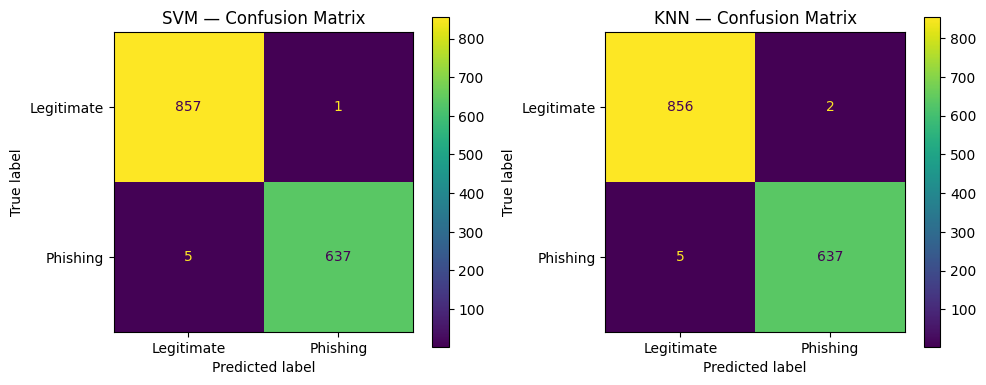

SVM classification report:
              precision    recall  f1-score   support

  Legitimate       0.99      1.00      1.00       858
    Phishing       1.00      0.99      1.00       642

    accuracy                           1.00      1500
   macro avg       1.00      1.00      1.00      1500
weighted avg       1.00      1.00      1.00      1500

KNN classification report:
              precision    recall  f1-score   support

  Legitimate       0.99      1.00      1.00       858
    Phishing       1.00      0.99      0.99       642

    accuracy                           1.00      1500
   macro avg       1.00      0.99      1.00      1500
weighted avg       1.00      1.00      1.00      1500



In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, svm_pred, labels=[0, 1], display_labels=["Legitimate", "Phishing"],
    values_format="d", ax=axes[0]
)
axes[0].set_title("SVM — Confusion Matrix")
ConfusionMatrixDisplay.from_predictions(
    y_test, knn_pred, labels=[0, 1], display_labels=["Legitimate", "Phishing"],
    values_format="d", ax=axes[1]
)
axes[1].set_title("KNN — Confusion Matrix")
plt.tight_layout()
plt.show()

print("SVM classification report:")
print(classification_report(y_test, svm_pred, target_names=["Legitimate", "Phishing"], zero_division=0))
print("KNN classification report:")
print(classification_report(y_test, knn_pred, target_names=["Legitimate", "Phishing"], zero_division=0))

## Step 9 — Investigate false positives and false negatives

The notebook deliberately does not display raw URLs. Instead, inspect the numeric features of examples that were misclassified by SVM and consider what additional evidence an analyst would need before taking action on a domain.

For example, URL structure alone may not be sufficient to distinguish a legitimate long URL from a well-crafted phishing URL. Useful additional evidence might include domain reputation, registration history, redirect behavior, page content, email context, or results from approved security tools. Such evidence is not included in the model used here, so treat these examples as a starting point for discussion rather than as a definitive investigation.


For safety and privacy, examine only the numeric features of misclassified examples; do not reveal or manually open the raw URLs. Identify examples of false positives and false negatives, compare their feature values, and write down what additional evidence you would request before recommending an action such as blocking a domain.


In [ ]:
review = X_test.copy()
review["actual_is_phishing"] = y_test
review["rule_prediction"] = rule_pred
review["svm_prediction"] = svm_pred
review["knn_prediction"] = knn_pred

print("SVM — false positives (legitimate URL incorrectly classified as phishing):")
display(review[(review.actual_is_phishing == 0) & (review.svm_prediction == 1)].head(5))
print("SVM — false negatives (phishing URL missed by the model):")
display(review[(review.actual_is_phishing == 1) & (review.svm_prediction == 0)].head(5))

SVM — false positives (legitimate URL incorrectly classified as phishing):


,URLLength,DomainLength,IsDomainIP,CharContinuationRate,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,...,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,actual_is_phishing,rule_prediction,svm_prediction,knn_prediction
2071,26,19,0,1.0,9,1,0,0,0.0,13,...,0,0,0,1,0.038,1,0,0,1,1


SVM — false negatives (phishing URL missed by the model):


,URLLength,DomainLength,IsDomainIP,CharContinuationRate,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,...,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,actual_is_phishing,rule_prediction,svm_prediction,knn_prediction
5289,27,18,0,1.000000,3,1,0,0,0.0,13,...,0,0,0,2,0.074,1,1,0,0,0
5402,30,22,0,0.857143,3,1,0,0,0.0,16,...,0,0,0,2,0.067,1,1,0,0,0
3304,26,16,0,1.000000,3,1,0,0,0.0,9,...,0,0,0,2,0.077,1,1,0,0,0
4559,31,24,0,0.823529,2,2,0,0,0.0,17,...,0,0,0,2,0.065,1,1,0,0,0
3809,21,14,0,1.000000,3,1,0,0,0.0,5,...,0,0,0,1,0.048,1,1,0,0,0


## Optional extension — Evaluate on unseen domains

This extension is intended for students who finish the core tasks early. It explores whether the results change when domains in the test set have not appeared in the training set.


A random split can place URLs from the same domain in both the training and test sets. If URLs from one domain share similar characteristics, this overlap may make the evaluation less challenging than predicting for a completely unseen domain.

To make the test more demanding, the notebook uses `Domain` **only as a grouping variable** to keep groups separate between training and test data. The `Domain` value is not supplied to the model as a feature. Compare the resulting metrics with the random-split metrics and discuss any differences.

This is still only an additional generalization check—not a complete temporal evaluation. It does not reproduce changes in attacker behavior over time, and the group split may produce a different class balance or sample size from the random split.


In [ ]:
group_split = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)
g_train_idx, g_test_idx = next(group_split.split(X, y, groups=groups))
X_train_g, X_test_g = X.iloc[g_train_idx], X.iloc[g_test_idx]
y_train_g, y_test_g = y.iloc[g_train_idx], y.iloc[g_test_idx]
train_domains = set(groups.iloc[g_train_idx])
test_domains = set(groups.iloc[g_test_idx])
print("Domains shared between training and test sets:", len(train_domains.intersection(test_domains)))
print("Training:", len(X_train_g), "| Test:", len(X_test_g))

group_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1.0, class_weight="balanced")
)
group_svm.fit(X_train_g, y_train_g)
group_pred = group_svm.predict(X_test_g)

display(pd.DataFrame([
    metric_row("SVM — random split", y_test, svm_pred),
    metric_row("SVM — unseen domains", y_test_g, group_pred),
]))

Domains shared between training and test sets: 0
Training: 4507 | Test: 1493


,Method,Accuracy,Precision phishing,Recall phishing,F1 phishing,False-positive rate
0,SVM — random split,0.996,0.998,0.992,0.995,0.001
1,SVM — unseen domains,0.998,0.998,0.997,0.998,0.001


## Step 10 — Zero Trust principle: a prediction is not authorization

A classifier estimates a label from the features it receives. It does not, by itself, establish that a domain is malicious or authorize a potentially disruptive response.

This final exercise illustrates a simple policy in which read-only analysis and reporting are allowed, while high-impact actions require human approval. The example is a teaching simulation only; it does not connect to security tools or perform real actions.


The policy simulation allows actions such as analyzing URL features or generating a report. Actions such as blocking a domain, quarantining an email, or disabling an account are treated as high impact and are denied unless a human approval flag is supplied.

Discuss why this separation matters. A real system would also need authentication, authorization controls, audit logging, reliable evidence, escalation procedures, and safeguards against erroneous or manipulated model predictions.


In [ ]:
READ_ONLY_ACTIONS = {"analyze_url_features", "generate_report"}
HIGH_IMPACT_ACTIONS = {"block_domain", "quarantine_email", "disable_account"}

def authorize_action(action, human_approved=False):
    if action in READ_ONLY_ACTIONS:
        decision = "ALLOW_READ_ONLY"
    elif action in HIGH_IMPACT_ACTIONS and human_approved:
        decision = "ALLOW_AFTER_HUMAN_APPROVAL"
    else:
        decision = "DENY"
    print({"action": action, "human_approved": human_approved, "decision": decision})
    return decision

authorize_action("generate_report")
authorize_action("block_domain")
authorize_action("block_domain", human_approved=True)

{'action': 'generate_report', 'human_approved': False, 'decision': 'ALLOW_READ_ONLY'}
{'action': 'block_domain', 'human_approved': False, 'decision': 'DENY'}
{'action': 'block_domain', 'human_approved': True, 'decision': 'ALLOW_AFTER_HUMAN_APPROVAL'}


'ALLOW_AFTER_HUMAN_APPROVAL'

## Activities — Experiment with hyperparameters

Now vary the model settings and compare the resulting metrics. The notebook tests several values of `C` for the RBF SVM and several neighbor counts for KNN while keeping the data split and evaluation procedure unchanged.

For SVM, `C` controls the trade-off between allowing training errors and penalizing misclassification. A smaller value imposes stronger regularization; a larger value penalizes training errors more heavily and may fit the training sample more closely. For KNN, `k` is the number of nearby training examples used for voting. A small `k` can be sensitive to local noise, while a larger `k` typically smooths the decision boundary but can overlook small, local patterns.

The notebook uses the distance-weighted KNN variant. For a more complete investigation, you could compare other settings, including uniform voting, or test additional values of `k`.


Do not automatically choose the model with the highest accuracy. In a phishing-detection workflow, a false negative can allow a threat to pass unnoticed, while false positives consume analyst time and may disrupt legitimate activity.

Compare phishing precision, phishing recall, F1-score, and false-positive rate. Explain which trade-off you would prioritize for the intended use case, and support your choice with the results rather than assuming one model is always best.
